# 🎯 [K07] 군 공지 자동 요약 - 공지 자동 요약·주간 브리핑 도우미 구현
### Google Colab 실습 환경 (일반행정·부대관리 / Level 2)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/edunlab/milicontent2/blob/main/uploads/K07/K07_solution.ipynb)

---

## 📌 1. 프로젝트 개요 및 배경

| 항목 | 내용 |
| :--- | :--- |
| **과정 분류** | 일반행정·부대관리 (Level 2) |
| **학습 소요 시간** | 10개 미션 (5일 / 총 20.0시간) |
| **환경 사양** | Python 3.10+, numpy, pandas, matplotlib, scipy, scikit-learn |

### 📖 프로젝트 목표
부대 공지는 부서마다 형식이 다르고 변경 공지가 뒤따라 나오기도 해, 장병이 최신 기한과 일정을 정확히 챙기기 어렵습니다. 이 프로젝트에서는 파이썬으로 가상 부대 공지를 구조화하고, 날짜·기한·연락처 추출, 핵심 문장 요약, 주제 분류, 변경 공지 연결, 주간 브리핑 생성까지 수행하는 '군 공지 자동 요약 도우미'를 단계별로 구현합니다. 자동 요약의 품질을 루브릭으로 평가하고 개선하는 과정을 통해 AI 결과를 검증하는 방법을 함께 익힙니다.

> **⚠️ [교육용 가상 데이터셋 원칙]**
> - 본 실습의 모든 데이터(공지, 규정, 일정 등)는 보안 규정을 준수하여 **코드 내 난수 및 가상 시나리오로 생성**됩니다.
> - 실제 부대 작전, 군사 기밀 및 개인 식별 정보는 일체 포함되지 않습니다.

---



In [1]:
# ============================================================================
# [Google Colab 환경 설정] 필수 라이브러리 설치 및 임포트
# ============================================================================
!pip install -q numpy pandas matplotlib scipy scikit-learn

import os
import sys
import time
import math
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# 그래프 영문 폰트 기본 설정 (환경 독립성 보장)
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False

print(f"실행 환경 준비 완료 (Python {sys.version.split()[0]})")


---

## 🎯 미션 01. 공지 데이터 구조 정의하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **가상 공지 12건을 번호·날짜·작성 부서·제목·본문 항목의 표로 구조화하고 형식을 검사합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **공지 데이터를 표로 바꾸고 부서별 공지 수와 본문 길이를 확인하고 유효성을 점검하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 4개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `공지 데이터 표, 형식 검사 함수와 시험 결과` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 데이터 구조화 — 공지를 일관된 구조로 정리하고 형식 오류를 잡아내는 검사를 만들었는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(공지 데이터 표, 형식 검사 함수와 시험 결과)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [2]:
"""가상 부대 공지 12건을 표 형태(번호·날짜·작성 부서·제목·본문)로 구조화하고, 빠진 항목이나 형식 오류가 없는지 검사한다."""
import re
import pandas as pd

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

REQUIRED = ["id", "date", "from", "title", "body"]


def check(notice):
    errs = [f"{k} 누락" for k in REQUIRED if not notice.get(k)]
    if notice.get("date") and not re.match(r"^\d{4}-\d{2}-\d{2}$", notice["date"]):
        errs.append("날짜 형식 오류(YYYY-MM-DD)")
    if notice.get("body") and len(notice["body"]) < 30:
        errs.append("본문이 너무 짧음")
    return errs


df = pd.DataFrame(NOTICES)
df["본문 글자수"] = df["body"].str.len()
print(df[["id", "date", "from", "title", "본문 글자수"]].to_string(index=False))
print(f"\n공지 {len(df)}건, 평균 본문 {df['본문 글자수'].mean():.0f}자, 작성 부서 {df['from'].nunique()}곳")
print("부서별 공지 수:", df["from"].value_counts().to_dict())

errors = {n["id"]: check(n) for n in NOTICES}
print("\n형식 검사 오류:", sum(len(v) for v in errors.values()), "건")

# 오류 데이터로 검사기 시험
bad = {"id": "N99", "date": "11/20", "from": "", "title": "시험", "body": "짧음"}
print("오류 주입 시험:", check(bad))


 id       date     from                 title  본문 글자수
N01 2026-11-02   대대 행정과    11월 정기 휴가 신청 접수 안내     183
N02 2026-11-02   대대 의무실         독감 예방접종 일정 안내     192
N03 2026-11-03   대대 군수과           동계 피복 보급 일정     146
N04 2026-11-03 대대 정보통신실   사이버 보안 점검 및 비밀번호 변경     175
N05 2026-11-04 대대 교육훈련과       11월 사격 훈련 일정 변경     145
N06 2026-11-04   대대 복지과    부대 내 복지시설 운영 시간 조정     144
N07 2026-11-05   대대 인사과         자기개발 지원 신청 안내     158
N08 2026-11-05   대대 행정과 11월 정기 휴가 신청 접수 기한 연장     105
N09 2026-11-06 대대 안전관리관        동절기 안전사고 예방 수칙     144
N10 2026-11-06   대대 의무실     독감 예방접종 3중대 일정 변경      96
N11 2026-11-09   대대 군수과            생활관 난방기 점검     119
N12 2026-11-09 대대 교육훈련과       AI 활용 교육 참가자 모집     163

공지 12건, 평균 본문 148자, 작성 부서 8곳
부서별 공지 수: {'대대 행정과': 2, '대대 의무실': 2, '대대 군수과': 2, '대대 교육훈련과': 2, '대대 정보통신실': 1, '대대 복지과': 1, '대대 인사과': 1, '대대 안전관리관': 1}

형식 검사 오류: 0 건
오류 주입 시험: ['from 누락', '날짜 형식 오류(YYYY-MM-DD)', '본문이 너무 짧음']


---

## 🎯 미션 02. 공지 문장 나누고 정리하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **공지 본문을 문장 단위로 나누고 요약하기 좋은 형태로 정리합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **마침표를 기준으로 문장을 나누되 숫자 사이 마침표(예: 2.5)는 나누지 않도록 규칙을 만들고, 공백과 괄호 표기를 정리하고 체계화하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 4개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `문장 분리·정리 함수, 공지별 문장 수 표` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 전처리 — 예외를 고려한 문장 분리 규칙을 만들고 결과를 확인했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(문장 분리·정리 함수, 공지별 문장 수 표)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [3]:
"""공지 본문을 문장 단위로 나누고, 공백·괄호 표기를 정리해 요약하기 좋은 형태로 바꾼다."""
import re
import pandas as pd

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]


def split_sentences(text):
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


def normalize(s):
    s = re.sub(r"\s+", " ", s)
    s = s.replace("( ", "(").replace(" )", ")")
    return s.strip()


rows = []
for n in NOTICES:
    sents = [normalize(s) for s in split_sentences(n["body"])]
    rows.append({"id": n["id"], "제목": n["title"], "문장 수": len(sents), "첫 문장": sents[0][:40] + "..."})
df = pd.DataFrame(rows)
print(df.to_string(index=False))
print(f"\n전체 문장 {df['문장 수'].sum()}개, 공지당 평균 {df['문장 수'].mean():.1f}문장")

print("\n[N01 문장 분리 예시]")
for i, s in enumerate(split_sentences(NOTICES[0]["body"]), 1):
    print(f" {i}. {s}")

# 문장 분리 규칙 점검: 숫자 사이 마침표(예: 2.5)는 나누지 않아야 한다
test = "사격 점수는 2.5점 이상입니다. 결과는 게시합니다."
print("\n규칙 점검:", split_sentences(test))


 id                    제목  문장 수                                        첫 문장
N01    11월 정기 휴가 신청 접수 안내     5     11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다....
N02         독감 예방접종 일정 안내     4 독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 ...
N03           동계 피복 보급 일정     3 동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부...
N04   사이버 보안 점검 및 비밀번호 변경     4   11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다....
N05       11월 사격 훈련 일정 변경     4 기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 ...
N06    부대 내 복지시설 운영 시간 조정     3 동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시...
N07         자기개발 지원 신청 안내     4 2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습...
N08 11월 정기 휴가 신청 접수 기한 연장     3 11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 ...
N09        동절기 안전사고 예방 수칙     5             동절기 안전사고 예방을 위해 다음 사항을 지킵니다....
N10     독감 예방접종 3중대 일정 변경     3 3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목)...
N11            생활관 난방기 점검     3    11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다....
N12       AI 활용 교육 참가자 모집     4               대대 자체 AI 활용 교육 참가자를 모집합니다....

전체 문장 45개, 

---

## 🎯 미션 03. 날짜·기한·연락처 뽑아내기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **정규표현식으로 날짜·시간·기한·연락처를 뽑아 핵심 정보 카드를 만듭니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **'11월 5일(목)', '18시까지', '내선 1101' 같은 표현을 찾는 규칙을 만들어 공지마다 핵심 정보를 추출 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 4개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `정보 추출 함수, 핵심 정보 카드, 추출 정확도` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 정보 추출·정확도 확인 — 핵심 정보를 추출하고 정답과 비교해 정확도와 한계를 확인했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(정보 추출 함수, 핵심 정보 카드, 추출 정확도)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [4]:
"""정규표현식으로 공지에서 날짜, 시간, 기한(~까지), 연락처를 뽑아 '핵심 정보 카드'를 만든다."""
import re
import pandas as pd

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

DATE_RE = re.compile(r"\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?")
TIME_RE = re.compile(r"\d{1,2}시(?:\s?\d{1,2}분)?(?:~\d{1,2}시(?:\s?\d{1,2}분)?)?|\d{2}:\d{2}~\d{2}:\d{2}")
DEADLINE_RE = re.compile(r"(\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?(?:\s?\d{1,2}시)?)\s?(?:까지)")
CONTACT_RE = re.compile(r"내선\s?\d{3,4}")

rows = []
for n in NOTICES:
    b = n["body"]
    rows.append({"id": n["id"], "제목": n["title"][:16],
                 "날짜": ", ".join(dict.fromkeys(DATE_RE.findall(b))) or "-",
                 "기한(까지)": ", ".join(DEADLINE_RE.findall(b)) or "-",
                 "연락처": ", ".join(CONTACT_RE.findall(b)) or "-"})
df = pd.DataFrame(rows)
print(df.to_string(index=False))

has_deadline = (df["기한(까지)"] != "-").sum()
print(f"\n기한이 있는 공지 {has_deadline}건 / 날짜가 있는 공지 {(df['날짜'] != '-').sum()}건 / 연락처가 있는 공지 {(df['연락처'] != '-').sum()}건")

# 정답(사람이 표시한 기한)과 비교해 추출 정확도 확인
GOLD = {"N01": "11월 5일(목) 18시", "N03": "11월 4일(수)", "N04": "11월 8일(일)", "N07": "11월 20일(금)",
        "N08": "11월 5일(목) 18시", "N12": "11월 16일(월)"}
hit = sum(1 for k, v in GOLD.items() if v in df.set_index("id").loc[k, "기한(까지)"])
print(f"기한 추출 정확도: {hit}/{len(GOLD)} ({hit / len(GOLD):.0%})")
print("참고: N08은 '18시에서 12시로 연장'이라 '까지' 앞의 기한만으로는 최신 기한(11월 6일 12시)을 놓친다. 미션 8에서 변경 공지를 연결해 해결한다.")


 id               제목                                 날짜        기한(까지)     연락처
N01 11월 정기 휴가 신청 접수                11월 5일(목), 11월 9일(월) 11월 5일(목) 18시 내선 1101
N02    독감 예방접종 일정 안내 11월 10일(화), 11월 12일(목), 11월 16일(월)    11월 12일(목)       -
N03      동계 피복 보급 일정               11월 6일(금), 11월 4일(수)     11월 4일(수)       -
N04 사이버 보안 점검 및 비밀번호               11월 9일(월), 11월 8일(일)     11월 8일(일)       -
N05  11월 사격 훈련 일정 변경              11월 6일(금), 11월 13일(금)             -       -
N06 부대 내 복지시설 운영 시간                           11월 9일(월)             -       -
N07    자기개발 지원 신청 안내                         11월 20일(금)    11월 20일(금)       -
N08 11월 정기 휴가 신청 접수        11월 5일(목), 11월 6일(금), 11월 9일             -       -
N09   동절기 안전사고 예방 수칙                                  -             -       -
N10 독감 예방접종 3중대 일정 변                         11월 12일(목)             -       -
N11       생활관 난방기 점검                         11월 11일(수)             -       -
N12  AI 활용 교육 참가자 모집             11월 23일(월), 11월 16일(월)    11월 1

---

## 🎯 미션 04. 핵심 문장 요약하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **TF-IDF로 문장 중요도를 계산해 공지마다 핵심 문장 2개를 고르는 추출 요약을 만듭니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **글자 조각(2~3그램) TF-IDF로 각 문장이 공지 전체 주제와 얼마나 가까운지 계산해 상위 문장을 원래 순서대로 비교 분석하여 최적 도구를 선정하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `추출 요약 함수, 공지별 요약과 압축률` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [선택] 요약 모델 구현 — 중요도 계산 원리에 따라 요약을 구현하고 결과를 확인했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(추출 요약 함수, 공지별 요약과 압축률)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [5]:
"""TF-IDF로 문장의 중요도를 계산해 공지마다 핵심 문장 2개를 고르는 추출 요약을 만든다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]


def split_sentences(text):
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


def summarize(text, k=2):
    sents = split_sentences(text)
    if len(sents) <= k:
        return sents
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))   # 한국어 형태소 분석기 없이 글자 조각 사용
    X = vec.fit_transform(sents)
    centroid = np.asarray(X.mean(axis=0))                            # 공지 전체의 평균 주제
    score = (X @ centroid.T).ravel()                                 # 평균 주제와 가까운 문장일수록 중요
    top = sorted(np.argsort(-score)[:k])
    return [sents[i] for i in top]


rows = []
for n in NOTICES:
    s = summarize(n["body"])
    rows.append({"id": n["id"], "제목": n["title"], "요약": " ".join(s),
                 "압축률": f"{len(' '.join(s)) / len(n['body']):.0%}"})
for r in rows[:6]:
    print(f"[{r['id']}] {r['제목']}  (압축률 {r['압축률']})\n  - {r['요약']}\n")
ratio = np.mean([len(r["요약"]) / len(n["body"]) for r, n in zip(rows, NOTICES)])
print(f"평균 압축률 {ratio:.0%} (원문 대비 요약 길이)")


[N01] 11월 정기 휴가 신청 접수 안내  (압축률 36%)
  - 11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다.

[N02] 독감 예방접종 일정 안내  (압축률 40%)
  - 독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.

[N03] 동계 피복 보급 일정  (압축률 68%)
  - 동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 제출합니다.

[N04] 사이버 보안 점검 및 비밀번호 변경  (압축률 46%)
  - 11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다.

[N05] 11월 사격 훈련 일정 변경  (압축률 70%)
  - 기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 2중대는 6일에 실내 교육(사격술 예비훈련)으로 대체하며, 장소는 대대 강당입니다.

[N06] 부대 내 복지시설 운영 시간 조정  (압축률 73%)
  - 동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 복지매장(PX) 운영 시간은 기존과 같습니다.

평균 압축률 58% (원문 대비 요약 길이)


---

## 🎯 미션 05. 요약 품질 평가하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **요약 품질 평가 루브릭을 만들어 자동 요약을 점수로 평가합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **핵심 정보 보존(50점), 길이 적정(20점), 사람이 쓴 정답 요약과의 겹침(30점)으로 루브릭을 정하고 공지 6건을 평가하고 품질을 비교하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `요약 평가 루브릭, 공지별 평가표, 원인 분석` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 품질 평가(루브릭) — 측정 가능한 루브릭으로 요약을 평가하고 약점의 원인을 찾았는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(요약 평가 루브릭, 공지별 평가표, 원인 분석)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [6]:
"""요약 품질 평가 루브릭(핵심 정보 보존, 길이, 정답 요약과의 겹침)을 만들어 미션 4의 요약을 점수로 평가한다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

# ---- 공통 함수: 문장 분리, 핵심 정보 추출, 추출 요약 ----
def split_sentences(text):
    """마침표·물음표 뒤 공백을 기준으로 문장을 나눈다."""
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


DATE_RE = re.compile(r"\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?")
TIME_RE = re.compile(r"\d{1,2}시(?:\s?\d{1,2}분)?(?:~\d{1,2}시(?:\s?\d{1,2}분)?)?|\d{2}:\d{2}~\d{2}:\d{2}")
DEADLINE_RE = re.compile(r"(\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?(?:\s?\d{1,2}시)?)\s?(?:까지|부터)")
CONTACT_RE = re.compile(r"내선\s?\d{3,4}")


def extract_info(text):
    """날짜, 시간, 기한, 연락처를 뽑는다."""
    return {"dates": sorted(set(DATE_RE.findall(text)), key=text.find),
            "times": sorted(set(TIME_RE.findall(text)), key=text.find),
            "deadlines": [m for m in DEADLINE_RE.findall(text)],
            "contacts": CONTACT_RE.findall(text)}


def summarize(text, k=2, boost=False):
    """TF-IDF(글자 2~3그램) 점수가 높은 문장 k개를 원래 순서대로 고른다.
    boost=True면 첫 문장은 TF-IDF로 고르고, 나머지는 아직 요약에 없는 날짜·연락처를 가장 많이 담은 문장으로 채운다."""
    sents = split_sentences(text)
    if len(sents) <= k:
        return sents
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    X = vec.fit_transform(sents)
    centroid = np.asarray(X.mean(axis=0))
    score = (X @ centroid.T).ravel()
    if not boost:
        return [sents[i] for i in sorted(np.argsort(-score)[:k])]
    chosen = [int(np.argmax(score))]
    covered = set(DATE_RE.findall(sents[chosen[0]]) + CONTACT_RE.findall(sents[chosen[0]]))
    while len(chosen) < k:
        gain = []
        for i, s in enumerate(sents):
            if i in chosen:
                continue
            new_info = set(DATE_RE.findall(s) + CONTACT_RE.findall(s)) - covered
            gain.append((len(new_info), score[i], i))
        _, _, best = max(gain)
        chosen.append(best)
        covered |= set(DATE_RE.findall(sents[best]) + CONTACT_RE.findall(sents[best]))
    return [sents[i] for i in sorted(chosen)]

# 사람이 작성한 정답 요약(평가 기준) [교육용가상자료]
GOLD = {
 "N01": "11월 정기 휴가 신청을 11월 5일 18시까지 분대장에게 제출, 결과는 11월 9일 게시.",
 "N02": "독감 예방접종 11월 10~12일 중대별 09시 의무실 앞 집합, 미접종자는 16일 추가 접종.",
 "N03": "동계 피복 11월 6일 13~17시 보급, 치수표는 11월 4일까지 제출, 교환은 당일만.",
 "N04": "11월 8일까지 업무용 비밀번호 변경(9자리 이상), 9~13일 보안 점검, 휴대전화 촬영 금지.",
 "N05": "2중대 사격 훈련 11월 6일에서 13일로 연기, 6일은 강당 실내 교육으로 대체.",
 "N06": "11월 9일부터 체력단련실 06~21시, 사이버지식정보방 18~21시 30분, 수요일 14~16시 소독.",
}


def rubric(notice, summary_text, gold):
    info = extract_info(notice["body"])
    key = info["dates"] + info["contacts"]
    kept = sum(1 for k in key if k.split("(")[0] in summary_text) / max(len(key), 1)        # 핵심 정보 보존율
    length_ok = 0.15 <= len(summary_text) / len(notice["body"]) <= 0.75                      # 길이 적정
    g = set(re.findall(r"[가-힣0-9]{2,}", gold)); s = set(re.findall(r"[가-힣0-9]{2,}", summary_text))
    overlap = len(g & s) / len(g)                                                           # 정답과 겹침
    score = 50 * kept + 20 * length_ok + 30 * overlap
    return {"보존율": round(kept, 2), "길이적정": length_ok, "정답겹침": round(overlap, 2), "점수": round(score, 1)}


rows = []
for n in NOTICES:
    if n["id"] in GOLD:
        s = " ".join(summarize(n["body"], 2))
        rows.append({"id": n["id"], **rubric(n, s, GOLD[n["id"]])})
df = pd.DataFrame(rows)
print("[평가 루브릭] 핵심 정보 보존 50점 + 길이 적정 20점 + 정답 요약과 겹침 30점")
print(df.to_string(index=False))
print(f"\n평균 점수 {df['점수'].mean():.1f}점, 보존율 평균 {df['보존율'].mean():.0%}")
weak = df.sort_values("점수").head(2)["id"].tolist()
print("점수가 낮은 공지:", weak, "-> 날짜·기한이 담긴 문장이 요약에서 빠진 경우가 많다(미션 6에서 개선).")


[평가 루브릭] 핵심 정보 보존 50점 + 길이 적정 20점 + 정답 요약과 겹침 30점
 id  보존율  길이적정  정답겹침   점수
N01 0.67  True  0.73 75.2
N02 1.00  True  0.46 83.8
N03 1.00  True  0.33 80.0
N04 1.00  True  0.31 79.2
N05 1.00  True  0.33 80.0
N06 1.00  True  0.33 80.0

평균 점수 79.7점, 보존율 평균 94%
점수가 낮은 공지: ['N01', 'N04'] -> 날짜·기한이 담긴 문장이 요약에서 빠진 경우가 많다(미션 6에서 개선).


---

## 🎯 미션 06. 요약 규칙 개선하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **날짜·연락처를 놓치지 않도록 요약 규칙을 개선하고 효과를 비교합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **첫 문장은 중요도로 고르고, 나머지는 아직 요약에 없는 날짜·연락처를 가장 많이 담은 문장으로 채우도록 규칙을 바꿉니다 과정을 진행하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `개선 요약 함수, 개선 전후 비교표` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 개선·최적화 — 평가 결과를 근거로 규칙을 개선하고 전후를 수치로 비교했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(개선 요약 함수, 개선 전후 비교표)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [7]:
"""요약에 아직 없는 날짜·연락처를 담은 문장을 우선 고르도록 요약 규칙을 개선하고, 12건 전체의 핵심 정보 보존율과 미션 5 루브릭 점수를 개선 전후로 비교한다."""
import re
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

# ---- 공통 함수: 문장 분리, 핵심 정보 추출, 추출 요약 ----
def split_sentences(text):
    """마침표·물음표 뒤 공백을 기준으로 문장을 나눈다."""
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


DATE_RE = re.compile(r"\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?")
TIME_RE = re.compile(r"\d{1,2}시(?:\s?\d{1,2}분)?(?:~\d{1,2}시(?:\s?\d{1,2}분)?)?|\d{2}:\d{2}~\d{2}:\d{2}")
DEADLINE_RE = re.compile(r"(\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?(?:\s?\d{1,2}시)?)\s?(?:까지|부터)")
CONTACT_RE = re.compile(r"내선\s?\d{3,4}")


def extract_info(text):
    """날짜, 시간, 기한, 연락처를 뽑는다."""
    return {"dates": sorted(set(DATE_RE.findall(text)), key=text.find),
            "times": sorted(set(TIME_RE.findall(text)), key=text.find),
            "deadlines": [m for m in DEADLINE_RE.findall(text)],
            "contacts": CONTACT_RE.findall(text)}


def summarize(text, k=2, boost=False):
    """TF-IDF(글자 2~3그램) 점수가 높은 문장 k개를 원래 순서대로 고른다.
    boost=True면 첫 문장은 TF-IDF로 고르고, 나머지는 아직 요약에 없는 날짜·연락처를 가장 많이 담은 문장으로 채운다."""
    sents = split_sentences(text)
    if len(sents) <= k:
        return sents
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    X = vec.fit_transform(sents)
    centroid = np.asarray(X.mean(axis=0))
    score = (X @ centroid.T).ravel()
    if not boost:
        return [sents[i] for i in sorted(np.argsort(-score)[:k])]
    chosen = [int(np.argmax(score))]
    covered = set(DATE_RE.findall(sents[chosen[0]]) + CONTACT_RE.findall(sents[chosen[0]]))
    while len(chosen) < k:
        gain = []
        for i, s in enumerate(sents):
            if i in chosen:
                continue
            new_info = set(DATE_RE.findall(s) + CONTACT_RE.findall(s)) - covered
            gain.append((len(new_info), score[i], i))
        _, _, best = max(gain)
        chosen.append(best)
        covered |= set(DATE_RE.findall(sents[best]) + CONTACT_RE.findall(sents[best]))
    return [sents[i] for i in sorted(chosen)]

GOLD = {
 "N01": "11월 정기 휴가 신청을 11월 5일 18시까지 분대장에게 제출, 결과는 11월 9일 게시.",
 "N02": "독감 예방접종 11월 10~12일 중대별 09시 의무실 앞 집합, 미접종자는 16일 추가 접종.",
 "N03": "동계 피복 11월 6일 13~17시 보급, 치수표는 11월 4일까지 제출, 교환은 당일만.",
 "N04": "11월 8일까지 업무용 비밀번호 변경(9자리 이상), 9~13일 보안 점검, 휴대전화 촬영 금지.",
 "N05": "2중대 사격 훈련 11월 6일에서 13일로 연기, 6일은 강당 실내 교육으로 대체.",
 "N06": "11월 9일부터 체력단련실 06~21시, 사이버지식정보방 18~21시 30분, 수요일 14~16시 소독.",
}


def rubric(notice, summary_text, gold):
    info = extract_info(notice["body"])
    key = info["dates"] + info["contacts"]
    kept = sum(1 for k in key if k.split("(")[0] in summary_text) / max(len(key), 1)
    length_ok = 0.15 <= len(summary_text) / len(notice["body"]) <= 0.75
    g = set(re.findall(r"[가-힣0-9]{2,}", gold)); s = set(re.findall(r"[가-힣0-9]{2,}", summary_text))
    return 50 * kept + 20 * length_ok + 30 * len(g & s) / len(g)


rows = []
for n in NOTICES:
    if n["id"] not in GOLD:
        continue
    before = " ".join(summarize(n["body"], 2))
    after = " ".join(summarize(n["body"], 2, boost=True))
    rows.append({"id": n["id"], "개선 전": round(rubric(n, before, GOLD[n["id"]]), 1),
                 "개선 후": round(rubric(n, after, GOLD[n["id"]]), 1)})
df = pd.DataFrame(rows)
df["변화"] = df["개선 후"] - df["개선 전"]
print(df.to_string(index=False))
print(f"\n평균 점수 {df['개선 전'].mean():.1f} -> {df['개선 후'].mean():.1f} ({df['변화'].mean():+.1f}점)")

def keep_rate(n, text):
    info = extract_info(n["body"])
    key = info["dates"] + info["contacts"]
    return sum(1 for x in key if x.split("(")[0] in text) / len(key) if key else None


rates = []
for n in NOTICES:
    b = keep_rate(n, " ".join(summarize(n["body"], 2)))
    a = keep_rate(n, " ".join(summarize(n["body"], 2, boost=True)))
    if b is not None:
        rates.append({"id": n["id"], "개선 전 보존율": round(b, 2), "개선 후 보존율": round(a, 2)})
r = pd.DataFrame(rates)
print("\n[12건 전체: 날짜·연락처 보존율]")
print(r.to_string(index=False))
print(f"평균 보존율 {r['개선 전 보존율'].mean():.0%} -> {r['개선 후 보존율'].mean():.0%}")

# 요약 길이(k)를 바꿔 보기
for k in [1, 2, 3]:
    sc = np.mean([rubric(n, " ".join(summarize(n["body"], k, boost=True)), GOLD[n["id"]]) for n in NOTICES if n["id"] in GOLD])
    print(f"문장 {k}개 요약 평균 점수: {sc:.1f}")


 id  개선 전  개선 후  변화
N01  75.2  75.2 0.0
N02  83.8  83.8 0.0
N03  80.0  80.0 0.0
N04  79.2  79.2 0.0
N05  80.0  80.0 0.0
N06  80.0  80.0 0.0

평균 점수 79.7 -> 79.7 (+0.0점)

[12건 전체: 날짜·연락처 보존율]
 id  개선 전 보존율  개선 후 보존율
N01      0.67      0.67
N02      1.00      1.00
N03      1.00      1.00
N04      1.00      1.00
N05      1.00      1.00
N06      1.00      1.00
N07      0.00      1.00
N08      1.00      1.00
N10      1.00      1.00
N11      1.00      1.00
N12      0.50      0.50
평균 보존율 83% -> 92%
문장 1개 요약 평균 점수: 53.4
문장 2개 요약 평균 점수: 79.7
문장 3개 요약 평균 점수: 71.6


---

## 🎯 미션 07. 공지 분류와 우선순위 정하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **공지를 주제별로 자동 분류하고 기한이 가까운 순으로 우선순위를 정합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **주제(휴가·행정, 훈련, 의무·보건, 보급·시설, 보안, 복지·자기개발, 안전)별 대표 단어와 공지의 유사도로 분류하고 정답과 비교해 정확도를 냅니다 과정을 진행하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 4개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `분류 결과와 정확도, 우선순위 목록` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [선택] 분류·우선순위 — 공지를 분류하고 정확도를 확인했으며 기한 기준 우선순위를 정했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(분류 결과와 정확도, 우선순위 목록)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [8]:
"""공지를 주제(휴가·행정, 훈련, 의무·보건, 보급·시설, 보안, 복지·자기개발, 안전)로 자동 분류하고, 기한이 가까운 순으로 우선순위를 매긴다."""
import re
import datetime as dt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

CATEGORIES = {
    "휴가·행정": "휴가 신청 접수 결과 게시 행정 서류 제출 추첨",
    "훈련": "사격 훈련 교육 일정 연기 실내 교육 강당 중대장",
    "의무·보건": "예방접종 의무실 발열 접종 진료 동상",
    "보급·시설": "피복 보급 치수 교환 난방기 점검 생활관 시설",
    "보안": "보안 점검 비밀번호 계정 촬영 전송 금지",
    "복지·자기개발": "체력단련실 사이버지식정보방 복지매장 운영 시간 자기개발 자격증 강좌 교육 참가",
    "안전": "안전사고 예방 전열기 결빙 차량 방한 2인 1조",
}
GOLD = {"N01": "휴가·행정", "N02": "의무·보건", "N03": "보급·시설", "N04": "보안", "N05": "훈련", "N06": "복지·자기개발",
        "N07": "복지·자기개발", "N08": "휴가·행정", "N09": "안전", "N10": "의무·보건", "N11": "보급·시설", "N12": "복지·자기개발"}

texts = [n["title"] + " " + n["body"] for n in NOTICES]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(texts + list(CATEGORIES.values()))
sim = cosine_similarity(vec.transform(texts), vec.transform(list(CATEGORIES.values())))
pred = [list(CATEGORIES)[i] for i in sim.argmax(axis=1)]

TODAY = dt.date(2026, 11, 5)
DL = re.compile(r"(\d{1,2})월\s?(\d{1,2})일[^.]*?까지")


def days_left(body):
    m = DL.search(body)
    if not m:
        return None
    return (dt.date(2026, int(m.group(1)), int(m.group(2))) - TODAY).days


rows = []
for n, p in zip(NOTICES, pred):
    d = days_left(n["body"])
    pri = "높음" if d is not None and 0 <= d <= 3 else ("보통" if d is not None and d >= 0 else "참고")
    rows.append({"id": n["id"], "제목": n["title"][:18], "분류": p, "정답": GOLD[n["id"]], "남은 일수": "-" if d is None else d, "우선순위": pri})
df = pd.DataFrame(rows)
acc = (df["분류"] == df["정답"]).mean()
order = {"높음": 0, "보통": 1, "참고": 2}
print(df.sort_values(by="우선순위", key=lambda s: s.map(order)).to_string(index=False))
print(f"\n기준일 {TODAY} / 분류 정확도 {acc:.0%} ({(df['분류'] == df['정답']).sum()}/{len(df)})")
print("틀린 분류:", df[df["분류"] != df["정답"]][["id", "분류", "정답"]].values.tolist() or "없음")
print("참고: 이미 기한이 지난 공지(남은 일수 음수)는 '참고'로 내린다.")


 id                 제목      분류      정답 남은 일수 우선순위
N01 11월 정기 휴가 신청 접수 안내   휴가·행정   휴가·행정     0   높음
N03        동계 피복 보급 일정   보급·시설   보급·시설     1   높음
N02      독감 예방접종 일정 안내   의무·보건   의무·보건     5   보통
N04 사이버 보안 점검 및 비밀번호 변      보안      보안     4   보통
N07      자기개발 지원 신청 안내 복지·자기개발 복지·자기개발    15   보통
N12    AI 활용 교육 참가자 모집      훈련 복지·자기개발    11   보통
N11         생활관 난방기 점검   보급·시설   보급·시설     6   보통
N05    11월 사격 훈련 일정 변경      훈련      훈련     -   참고
N08 11월 정기 휴가 신청 접수 기한   휴가·행정   휴가·행정     -   참고
N06 부대 내 복지시설 운영 시간 조정 복지·자기개발 복지·자기개발     -   참고
N10  독감 예방접종 3중대 일정 변경   의무·보건   의무·보건     -   참고
N09     동절기 안전사고 예방 수칙      안전      안전     -   참고

기준일 2026-11-05 / 분류 정확도 92% (11/12)
틀린 분류: [['N12', '훈련', '복지·자기개발']]
참고: 이미 기한이 지난 공지(남은 일수 음수)는 '참고'로 내린다.


---

## 🎯 미션 08. 변경 공지 연결하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **앞선 공지를 고치는 변경 공지를 찾아 원래 공지와 연결하고 최신 정보로 갱신합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **제목 유사도와 '변경·연장·연기' 단어로 변경 공지를 찾아 원래 공지와 연결 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `변경 공지 연결표, 최신 정보 카드` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 오류 점검·갱신 — 변경 공지를 찾아 연결하고 지난 정보가 남지 않도록 갱신했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(변경 공지 연결표, 최신 정보 카드)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [9]:
"""제목 유사도와 '변경·연장·연기' 단어로 기존 공지를 고치는 변경 공지를 찾아 원래 공지와 연결하고, 최신 정보로 갱신한다."""
import re
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

CHANGE_WORDS = ("변경", "연장", "연기", "정정", "취소")
titles = [n["title"] for n in NOTICES]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(titles)
S = cosine_similarity(vec.transform(titles))

links = []
for i, n in enumerate(NOTICES):
    if not any(w in n["title"] for w in CHANGE_WORDS):
        continue
    cands = [(S[i, j], j) for j in range(len(NOTICES)) if j != i and NOTICES[j]["date"] <= n["date"]
             and not any(w in NOTICES[j]["title"] for w in CHANGE_WORDS)]
    score, j = max(cands)
    if score >= 0.3:
        links.append({"변경 공지": n["id"], "원래 공지": NOTICES[j]["id"], "제목 유사도": round(score, 2),
                      "원래 제목": NOTICES[j]["title"]})
print(pd.DataFrame(links).to_string(index=False))

# 변경 내용 반영: 'A에서 B로' 패턴으로 바뀐 값을 찾아 최신 정보 카드 생성
CHG = re.compile(r"(\d{1,2}월\s?\d{1,2}일\([^)]+\)\s?\d{1,2}시)에서\s?(\d{1,2}월\s?\d{1,2}일\([^)]+\)\s?\d{1,2}시)")
byid = {n["id"]: n for n in NOTICES}
print("\n[최신 정보로 갱신]")
for l in links:
    m = CHG.search(byid[l["변경 공지"]]["body"])
    if m:
        print(f" {l['원래 공지']} '{l['원래 제목']}': {m.group(1)} -> {m.group(2)} (근거 {l['변경 공지']})")
print("\n변경 공지를 연결하지 않으면 '휴가 신청 기한 11월 5일 18시', '3중대 접종 09시'처럼 지난 정보가 요약에 남는다.")


변경 공지 원래 공지  제목 유사도              원래 제목
  N08   N01    0.75 11월 정기 휴가 신청 접수 안내
  N10   N02    0.68      독감 예방접종 일정 안내

[최신 정보로 갱신]
 N01 '11월 정기 휴가 신청 접수 안내': 11월 5일(목) 18시 -> 11월 6일(금) 12시 (근거 N08)
 N02 '독감 예방접종 일정 안내': 11월 12일(목) 09시 -> 11월 12일(목) 14시 (근거 N10)

변경 공지를 연결하지 않으면 '휴가 신청 기한 11월 5일 18시', '3중대 접종 09시'처럼 지난 정보가 요약에 남는다.


---

## 🎯 미션 09. 주간 공지 브리핑 만들기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **한 주 공지를 모아 기한표, 분류별 요약, 변경 사항을 담은 주간 브리핑을 자동 생성합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **기한이 있는 일, 분류별 한 줄 요약, 변경 사항 세 부분으로 브리핑을 만들고 분류별 공지 수 그래프를 그립니다 과정을 진행하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 3개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `주간 공지 브리핑, 분류별 공지 수 그래프` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 종합 정리 — 여러 기능을 조합해 읽기 쉬운 주간 브리핑을 자동 생성했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(주간 공지 브리핑, 분류별 공지 수 그래프)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



[주간 공지 브리핑 - 가상 한빛대대, 2026-11-02~11-09] [교육용가상자료]

1. 기한이 있는 일
   - 11월 5일(목) 18시까지: 11월 정기 휴가 신청 접수 안내 (대대 행정과)
   - 11월 12일(목)까지: 독감 예방접종 일정 안내 (대대 의무실)
   - 11월 4일(수)까지: 동계 피복 보급 일정 (대대 군수과)
   - 11월 8일(일)까지: 사이버 보안 점검 및 비밀번호 변경 (대대 정보통신실)
   - 11월 20일(금)까지: 자기개발 지원 신청 안내 (대대 인사과)
   - 11월 16일(월)까지: AI 활용 교육 참가자 모집 (대대 교육훈련과)

2. 분류별 요약
   [휴가·행정]
   - 11월 정기 휴가 신청 접수 안내: 11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다.
   - 11월 정기 휴가 신청 접수 기한 연장: 결과 게시일(11월 9일)은 변경 없습니다.
   [훈련]
   - 11월 사격 훈련 일정 변경: 2중대는 6일에 실내 교육(사격술 예비훈련)으로 대체하며, 장소는 대대 강당입니다.
   [의무·보건]
   - 독감 예방접종 일정 안내: 독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다.
   - 독감 예방접종 3중대 일정 변경: 1중대와 2중대 일정은 변경 없습니다.
   [보급·시설]
   - 동계 피복 보급 일정: 동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다.
   - 생활관 난방기 점검: 11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다.
   [보안]
   - 사이버 보안 점검 및 비밀번호 변경: 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다.
   [복지·자기개발]
   - 부대 내 복지시설 운영 시간 조정: 동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분

<string>:166: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


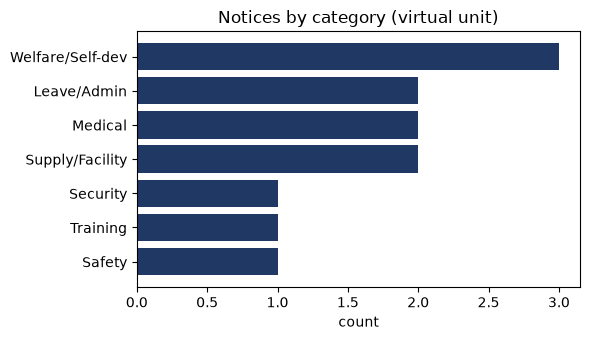

In [10]:
"""한 주 공지를 모아 기한표, 분류별 요약, 변경 사항을 담은 '주간 공지 브리핑'을 자동으로 만든다."""
import re
import datetime as dt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

# ---- 공통 함수: 문장 분리, 핵심 정보 추출, 추출 요약 ----
def split_sentences(text):
    """마침표·물음표 뒤 공백을 기준으로 문장을 나눈다."""
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


DATE_RE = re.compile(r"\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?")
TIME_RE = re.compile(r"\d{1,2}시(?:\s?\d{1,2}분)?(?:~\d{1,2}시(?:\s?\d{1,2}분)?)?|\d{2}:\d{2}~\d{2}:\d{2}")
DEADLINE_RE = re.compile(r"(\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?(?:\s?\d{1,2}시)?)\s?(?:까지|부터)")
CONTACT_RE = re.compile(r"내선\s?\d{3,4}")


def extract_info(text):
    """날짜, 시간, 기한, 연락처를 뽑는다."""
    return {"dates": sorted(set(DATE_RE.findall(text)), key=text.find),
            "times": sorted(set(TIME_RE.findall(text)), key=text.find),
            "deadlines": [m for m in DEADLINE_RE.findall(text)],
            "contacts": CONTACT_RE.findall(text)}


def summarize(text, k=2, boost=False):
    """TF-IDF(글자 2~3그램) 점수가 높은 문장 k개를 원래 순서대로 고른다.
    boost=True면 첫 문장은 TF-IDF로 고르고, 나머지는 아직 요약에 없는 날짜·연락처를 가장 많이 담은 문장으로 채운다."""
    sents = split_sentences(text)
    if len(sents) <= k:
        return sents
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    X = vec.fit_transform(sents)
    centroid = np.asarray(X.mean(axis=0))
    score = (X @ centroid.T).ravel()
    if not boost:
        return [sents[i] for i in sorted(np.argsort(-score)[:k])]
    chosen = [int(np.argmax(score))]
    covered = set(DATE_RE.findall(sents[chosen[0]]) + CONTACT_RE.findall(sents[chosen[0]]))
    while len(chosen) < k:
        gain = []
        for i, s in enumerate(sents):
            if i in chosen:
                continue
            new_info = set(DATE_RE.findall(s) + CONTACT_RE.findall(s)) - covered
            gain.append((len(new_info), score[i], i))
        _, _, best = max(gain)
        chosen.append(best)
        covered |= set(DATE_RE.findall(sents[best]) + CONTACT_RE.findall(sents[best]))
    return [sents[i] for i in sorted(chosen)]

CATS = {"휴가·행정": "휴가 신청 접수 결과 게시 행정", "훈련": "사격 훈련 교육 일정 연기 강당",
        "의무·보건": "예방접종 의무실 발열 접종", "보급·시설": "피복 보급 치수 난방기 점검 생활관",
        "보안": "보안 점검 비밀번호 계정 촬영", "복지·자기개발": "체력단련실 사이버지식정보방 자기개발 자격증 교육 참가",
        "안전": "안전사고 예방 전열기 결빙 방한"}
texts = [n["title"] + " " + n["body"] for n in NOTICES]
vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(texts + list(CATS.values()))
cat = [list(CATS)[i] for i in cosine_similarity(vec.transform(texts), vec.transform(list(CATS.values()))).argmax(1)]

lines = ["[주간 공지 브리핑 - 가상 한빛대대, 2026-11-02~11-09] [교육용가상자료]", ""]
lines.append("1. 기한이 있는 일")
for n in NOTICES:
    for d in DEADLINE_RE.findall(n["body"]):
        if "까지" in n["body"].split(d, 1)[1][:4]:
            lines.append(f"   - {d}까지: {n['title']} ({n['from']})")
lines.append("\n2. 분류별 요약")
for c in CATS:
    items = [n for n, k in zip(NOTICES, cat) if k == c]
    if items:
        lines.append(f"   [{c}]")
        for n in items:
            lines.append(f"   - {n['title']}: {summarize(n['body'], 1, boost=True)[0]}")
lines.append("\n3. 변경 사항")
for n in NOTICES:
    if any(w in n["title"] for w in ("일정 변경", "연장", "연기")):
        lines.append(f"   - {n['title']} ({n['date']})")
lines.append("\n※ 자동 요약은 원문을 대신하지 않는다. 일정·기한은 원문 공지와 담당 부서에서 최종 확인한다.")
print("\n".join(lines))

EN = {"휴가·행정": "Leave/Admin", "훈련": "Training", "의무·보건": "Medical", "보급·시설": "Supply/Facility",
      "보안": "Security", "복지·자기개발": "Welfare/Self-dev", "안전": "Safety"}
counts = pd.Series(cat).value_counts()
plt.figure(figsize=(6, 3.5))
plt.barh([EN[c] for c in counts.index][::-1], counts.values[::-1], color="#1F3864")
plt.title("Notices by category (virtual unit)")
plt.xlabel("count"); plt.tight_layout(); plt.show()


---

## 🎯 미션 10. 공지 자동 요약 도우미 완성하기
**소요시간**: 약 2.0시간

### 📋 미션 배경 및 수행 지침
#### 미션 배경 및 당위성

실제 부대 실무 현장에서는 불명확한 정보 전달이나 수동 업무 처리로 인해 불필요한 행정 소요가 발생하고 주요 공지·규정 확인이 지연되는 문제가 발생하기 쉽습니다. 따라서 **전체 기능을 하나로 묶은 공지 자동 요약 도우미를 완성하고 자체 점검합니다.** 과업을 체계적으로 수행하여 현장 업무 효율성을 극대화하고 정보 누락으로 인한 혼선을 사전에 방지해야 합니다.

이 문제를 해결하기 위해 본 미션에서는 **구조 검사, 요약, 정보 추출, 분류, 변경 공지 연결을 하나의 도우미로 통합하고 공지 카드를 출력 수행하고 검증하는** 실습을 단계별로 수행합니다.

학습자는 실습가이드에 제시된 총 4개 세부 활동을 순차적으로 진행하며 핵심 산출물을 도출하고 검증 기준을 달성합니다.

**이번 미션 결과물:** `공지 자동 요약 도우미 코드, 자체 점검 결과, 검토용 프롬프트` 완성

### 🔍 평가 및 검증 기준 (PASS 조건)
#### 미션 판정

**평가 구분:** 필수

**핵심 평가 기준:** [필수] 통합·완성 — 도우미를 통합하고 자체 점검을 모두 통과했으며 사람의 원문 확인 절차를 명시했는가? (PASS / FAIL)

#### 미션 PASS 조건

- 요구 산출물(공지 자동 요약 도우미 코드, 자체 점검 결과, 검토용 프롬프트)의 완성도 충족


- 원문 대조 점검을 통한 사실 검증 및 정확성 확보


- 교육용 가상 데이터 활용 및 군사보안 수칙 엄수


#### 채점자 판정 메모

> 단순 결과물 생성 여부뿐만 아니라 AI 결과물의 오류를 직접 찾아내고 바로잡았는지 대조표를 확인한다.



In [11]:
"""구조화, 요약, 정보 추출, 분류, 변경 공지 연결, 브리핑 생성을 하나로 묶은 '군 공지 자동 요약 도우미'를 완성하고 자체 점검한다."""
import re
import datetime as dt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# ---------------------------------------------------------------------------
# [교육용가상자료] 가상 한빛대대 자료 (실제 부대·규정·인물과 무관)
# ---------------------------------------------------------------------------
NOTICES = [{'id': 'N01',
  'date': '2026-11-02',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 안내',
  'body': '11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 신청은 중대 행정반에 비치된 휴가 신청서를 작성하여 소속 분대장에게 제출합니다. 휴가 기간이 겹치는 인원이 '
          '중대 정원의 20%를 넘으면 선착순이 아닌 추첨으로 조정합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다. 문의: 행정과 담당관(내선 1101).'},
 {'id': 'N02',
  'date': '2026-11-02',
  'from': '대대 의무실',
  'title': '독감 예방접종 일정 안내',
  'body': '독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 1중대는 10일 09시, 2중대는 11일 09시, 3중대는 12일 09시에 의무실 앞으로 '
          '집합합니다. 접종 당일 발열이 있는 인원은 접종 전 의무병에게 알리고, 접종 후 30분간 의무실 대기 후 복귀합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.'},
 {'id': 'N03',
  'date': '2026-11-03',
  'from': '대대 군수과',
  'title': '동계 피복 보급 일정',
  'body': '동계 피복(방한 내피, 방한 장갑, 넥워머)을 11월 6일(금) 13시부터 17시까지 중대 순서대로 보급합니다. 분대장은 분대원 치수표를 11월 4일(수)까지 군수과에 '
          '제출합니다. 치수 교환은 보급 당일에만 가능하며, 이후에는 다음 달 정기 보급 때 교환합니다.'},
 {'id': 'N04',
  'date': '2026-11-03',
  'from': '대대 정보통신실',
  'title': '사이버 보안 점검 및 비밀번호 변경',
  'body': '11월 9일(월)부터 13일(금)까지 사이버 보안 점검을 실시합니다. 모든 인원은 11월 8일(일)까지 업무용 계정 비밀번호를 변경해야 합니다. 비밀번호는 '
          '영문·숫자·특수문자를 포함해 9자리 이상으로 설정하고, 이전 비밀번호와 같으면 안 됩니다. 개인 휴대전화로 업무 자료를 촬영하거나 전송하는 행위는 금지됩니다.'},
 {'id': 'N05',
  'date': '2026-11-04',
  'from': '대대 교육훈련과',
  'title': '11월 사격 훈련 일정 변경',
  'body': '기상 악화 예보로 11월 6일(금) 예정이던 2중대 사격 훈련을 11월 13일(금)로 연기합니다. 1중대와 3중대 일정은 변경 없습니다. 2중대는 6일에 실내 교육(사격술 '
          '예비훈련)으로 대체하며, 장소는 대대 강당입니다. 세부 시간표는 중대장 지시에 따릅니다.'},
 {'id': 'N06',
  'date': '2026-11-04',
  'from': '대대 복지과',
  'title': '부대 내 복지시설 운영 시간 조정',
  'body': '동절기를 맞아 11월 9일(월)부터 체력단련실 운영 시간을 06시~21시로, 사이버지식정보방 운영 시간을 18시~21시 30분으로 조정합니다. 매주 수요일 14시~16시는 '
          '체력단련실 소독으로 이용할 수 없습니다. 복지매장(PX) 운영 시간은 기존과 같습니다.'},
 {'id': 'N07',
  'date': '2026-11-05',
  'from': '대대 인사과',
  'title': '자기개발 지원 신청 안내',
  'body': '2027년 상반기 자기개발 비용 지원 신청을 11월 20일(금)까지 받습니다. 지원 대상은 자격증 응시료와 온라인 강좌 수강료이며, 1인당 연간 한도 내에서 실비를 '
          '지원합니다. 신청 시 응시 확인서 또는 수강 등록 확인서를 첨부합니다. 지원 여부는 12월 첫째 주에 개별 통보합니다.'},
 {'id': 'N08',
  'date': '2026-11-05',
  'from': '대대 행정과',
  'title': '11월 정기 휴가 신청 접수 기한 연장',
  'body': '11월 정기 휴가 신청 접수 기한을 11월 5일(목) 18시에서 11월 6일(금) 12시로 연장합니다. 사격 훈련 일정 변경에 따른 조치입니다. 결과 게시일(11월 9일)은 '
          '변경 없습니다.'},
 {'id': 'N09',
  'date': '2026-11-06',
  'from': '대대 안전관리관',
  'title': '동절기 안전사고 예방 수칙',
  'body': '동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다. 차량 운행 전 타이어 상태와 결빙 구간을 확인합니다. 야외 활동 시 방한 장구를 '
          '착용하고 2인 1조로 움직입니다. 동상 의심 증상이 있으면 즉시 의무실에 알립니다.'},
 {'id': 'N10',
  'date': '2026-11-06',
  'from': '대대 의무실',
  'title': '독감 예방접종 3중대 일정 변경',
  'body': '3중대 독감 예방접종을 11월 12일(목) 09시에서 11월 12일(목) 14시로 변경합니다. 오전 훈련 일정 조정에 따른 것입니다. 1중대와 2중대 일정은 변경 없습니다.'},
 {'id': 'N11',
  'date': '2026-11-09',
  'from': '대대 군수과',
  'title': '생활관 난방기 점검',
  'body': '11월 11일(수)부터 13일(금)까지 생활관 난방기를 점검합니다. 점검 시간에는 생활관을 비워 두고, 귀중품은 개인 관물대에 보관합니다. 난방기 이상 소음이나 냄새가 있으면 '
          '점검 전까지 중대 행정반에 신고합니다.'},
 {'id': 'N12',
  'date': '2026-11-09',
  'from': '대대 교육훈련과',
  'title': 'AI 활용 교육 참가자 모집',
  'body': '대대 자체 AI 활용 교육 참가자를 모집합니다. 교육은 11월 23일(월)부터 4주간 매주 월요일 19시~21시에 사이버지식정보방에서 진행합니다. 중대별 5명 이내로 11월 '
          '16일(월)까지 중대 행정반에 신청합니다. 부대 자료를 외부 AI 서비스에 입력하지 않는 보안 수칙 교육이 포함됩니다.'}]

# ---- 공통 함수: 문장 분리, 핵심 정보 추출, 추출 요약 ----
def split_sentences(text):
    """마침표·물음표 뒤 공백을 기준으로 문장을 나눈다."""
    parts = re.split(r"(?<=[.?!])\s+", text.strip())
    return [p.strip() for p in parts if p.strip()]


DATE_RE = re.compile(r"\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?")
TIME_RE = re.compile(r"\d{1,2}시(?:\s?\d{1,2}분)?(?:~\d{1,2}시(?:\s?\d{1,2}분)?)?|\d{2}:\d{2}~\d{2}:\d{2}")
DEADLINE_RE = re.compile(r"(\d{1,2}월\s?\d{1,2}일(?:\([월화수목금토일]\))?(?:\s?\d{1,2}시)?)\s?(?:까지|부터)")
CONTACT_RE = re.compile(r"내선\s?\d{3,4}")


def extract_info(text):
    """날짜, 시간, 기한, 연락처를 뽑는다."""
    return {"dates": sorted(set(DATE_RE.findall(text)), key=text.find),
            "times": sorted(set(TIME_RE.findall(text)), key=text.find),
            "deadlines": [m for m in DEADLINE_RE.findall(text)],
            "contacts": CONTACT_RE.findall(text)}


def summarize(text, k=2, boost=False):
    """TF-IDF(글자 2~3그램) 점수가 높은 문장 k개를 원래 순서대로 고른다.
    boost=True면 첫 문장은 TF-IDF로 고르고, 나머지는 아직 요약에 없는 날짜·연락처를 가장 많이 담은 문장으로 채운다."""
    sents = split_sentences(text)
    if len(sents) <= k:
        return sents
    vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3))
    X = vec.fit_transform(sents)
    centroid = np.asarray(X.mean(axis=0))
    score = (X @ centroid.T).ravel()
    if not boost:
        return [sents[i] for i in sorted(np.argsort(-score)[:k])]
    chosen = [int(np.argmax(score))]
    covered = set(DATE_RE.findall(sents[chosen[0]]) + CONTACT_RE.findall(sents[chosen[0]]))
    while len(chosen) < k:
        gain = []
        for i, s in enumerate(sents):
            if i in chosen:
                continue
            new_info = set(DATE_RE.findall(s) + CONTACT_RE.findall(s)) - covered
            gain.append((len(new_info), score[i], i))
        _, _, best = max(gain)
        chosen.append(best)
        covered |= set(DATE_RE.findall(sents[best]) + CONTACT_RE.findall(sents[best]))
    return [sents[i] for i in sorted(chosen)]

CATS = {"휴가·행정": "휴가 신청 접수 결과 게시 행정", "훈련": "사격 훈련 교육 일정 연기 강당",
        "의무·보건": "예방접종 의무실 발열 접종", "보급·시설": "피복 보급 치수 난방기 점검 생활관",
        "보안": "보안 점검 비밀번호 계정 촬영", "복지·자기개발": "체력단련실 사이버지식정보방 자기개발 자격증 교육 참가",
        "안전": "안전사고 예방 전열기 결빙 방한"}
CHANGE = ("변경", "연장", "연기", "정정", "취소")


class NoticeAssistant:
    def __init__(self, notices):
        self.notices = [n for n in notices if all(n.get(k) for k in ("id", "date", "from", "title", "body"))]
        self.rejected = [n.get("id", "?") for n in notices if n not in self.notices]
        texts = [n["title"] + " " + n["body"] for n in self.notices]
        self.vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit(texts + list(CATS.values()))
        sim = cosine_similarity(self.vec.transform(texts), self.vec.transform(list(CATS.values())))
        for n, i in zip(self.notices, sim.argmax(1)):
            n["category"] = list(CATS)[i]
            n["summary"] = " ".join(summarize(n["body"], 2, boost=True))
            n["info"] = extract_info(n["body"])
        self.links = self._link_changes()

    def _link_changes(self):
        tv = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 3)).fit([n["title"] for n in self.notices])
        T = tv.transform([n["title"] for n in self.notices])
        S = cosine_similarity(T)
        out = {}
        for i, n in enumerate(self.notices):
            if any(w in n["title"] for w in CHANGE):
                c = [(S[i, j], j) for j in range(len(self.notices)) if j != i and not any(w in self.notices[j]["title"] for w in CHANGE)]
                s, j = max(c)
                if s >= 0.3:
                    out[n["id"]] = self.notices[j]["id"]
        return out

    def card(self, nid):
        n = next(x for x in self.notices if x["id"] == nid)
        upd = [k for k, v in self.links.items() if v == nid]
        return (f"[{n['category']}] {n['title']} ({n['from']}, {n['date']})\n  요약: {n['summary']}\n"
                f"  날짜: {', '.join(n['info']['dates']) or '-'} / 연락처: {', '.join(n['info']['contacts']) or '-'}"
                + (f"\n  변경 공지 있음: {', '.join(upd)} - 최신 내용 확인 필요" if upd else ""))


data = NOTICES + [{"id": "N13", "date": "2026-11-09", "from": "", "title": "작성 부서 누락 공지", "body": "부서가 비어 있는 시험용 공지입니다."}]
t0 = dt.datetime.now()
A = NoticeAssistant(data)
elapsed = (dt.datetime.now() - t0).total_seconds()
print(A.card("N01")); print(A.card("N02")); print(A.card("N09"))

checks = {
    "형식 오류 공지 차단(N13)": A.rejected == ["N13"],
    "12건 모두 요약 생성": all(n["summary"] for n in A.notices) and len(A.notices) == 12,
    "요약이 원문보다 짧음": all(len(n["summary"]) < len(n["body"]) for n in A.notices),
    "변경 공지 2건 연결(N08->N01, N10->N02)": A.links == {"N08": "N01", "N10": "N02"},
    "모든 공지에 분류 부여": all(n["category"] in CATS for n in A.notices),
    "처리 시간 5초 이내": elapsed < 5,
}
print()
for k, v in checks.items():
    print(f"[{'PASS' if v else 'FAIL'}] {k}")
print(f"자체 점검 {sum(checks.values())}/{len(checks)} 통과")

print("\n[생성형 AI로 검토할 때 쓰는 프롬프트 예시]")
print("너는 부대 공지를 정리하는 행정병이다. 아래 원문과 자동 요약을 비교해 빠진 날짜·기한·대상이 있으면 지적하라. "
      "원문에 없는 내용은 만들지 말라. (원문과 요약은 교육용 가상 자료만 사용)")
print("\n※ 자동 요약은 보조 도구이며, 공지 게시와 일정 확정은 담당 부서와 지휘계통이 원문으로 확인한다.")


[휴가·행정] 11월 정기 휴가 신청 접수 안내 (대대 행정과, 2026-11-02)
  요약: 11월 정기 휴가 신청을 11월 5일(목) 18시까지 접수합니다. 결과는 11월 9일(월) 중대 게시판에 게시합니다.
  날짜: 11월 5일(목), 11월 9일(월) / 연락처: 내선 1101
  변경 공지 있음: N08 - 최신 내용 확인 필요
[의무·보건] 독감 예방접종 일정 안내 (대대 의무실, 2026-11-02)
  요약: 독감 예방접종을 11월 10일(화)부터 11월 12일(목)까지 중대별로 실시합니다. 미접종자는 11월 16일(월) 추가 접종을 받습니다.
  날짜: 11월 10일(화), 11월 12일(목), 11월 16일(월) / 연락처: -
  변경 공지 있음: N10 - 최신 내용 확인 필요
[안전] 동절기 안전사고 예방 수칙 (대대 안전관리관, 2026-11-06)
  요약: 동절기 안전사고 예방을 위해 다음 사항을 지킵니다. 생활관 내 개인 전열기 사용을 금지합니다.
  날짜: - / 연락처: -

[PASS] 형식 오류 공지 차단(N13)
[PASS] 12건 모두 요약 생성
[PASS] 요약이 원문보다 짧음
[PASS] 변경 공지 2건 연결(N08->N01, N10->N02)
[PASS] 모든 공지에 분류 부여
[PASS] 처리 시간 5초 이내
자체 점검 6/6 통과

[생성형 AI로 검토할 때 쓰는 프롬프트 예시]
너는 부대 공지를 정리하는 행정병이다. 아래 원문과 자동 요약을 비교해 빠진 날짜·기한·대상이 있으면 지적하라. 원문에 없는 내용은 만들지 말라. (원문과 요약은 교육용 가상 자료만 사용)

※ 자동 요약은 보조 도구이며, 공지 게시와 일정 확정은 담당 부서와 지휘계통이 원문으로 확인한다.
